# BankReach: Bank Term Deposit Subscription Prediction Using Machine Learning

## Exploratory Data Analysis and Initial Data Preparation

This notebook presents the first stages of the BankReach machine learning project. It covers problem definition, data collection, initial dataset inspection, data cleaning and preprocessing, and exploratory data analysis (EDA). The results will serve as the basis for the next stages of feature engineering and model development.



## Import Libraries

The following libraries are used for data handling, numerical operations, data visualization, and machine learning.

In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Scikit-learn:", sklearn.__version__)


Pandas: 3.1.1
NumPy: 2.5.4
Matplotlib: 3.11.2
Seaborn: 0.13.2
Scikit-learn: 1.9.1


## Load the Dataset

The dataset is read from the CSV file using a semicolon (`;`) as the separator.

The CSV file is stored in the `dataset` folder within the project directory. A relative file path is used so the notebook can access the dataset when the project is shared with my group members.

In [2]:
df = pd.read_csv("dataset/bank-full.csv", sep=";")

print("Dataset successfully loaded!")
print("Dataset Shape:", df.shape)


Dataset successfully loaded!
Dataset Shape: (45211, 17)


# 1. Problem Definition

## 1.1 Project Overview

BankReach is a machine learning project that aims to predict whether a bank customer will subscribe to a term deposit after being contacted during a marketing campaign. The project uses historical customer and campaign data from the Bank Marketing dataset.

## 1.2 Problem Type

This project is a **Binary Classification Task** because the model will predict one of two possible outcomes: whether a customer subscribed to a term deposit or not.

## 1.3 Target Variable

The target variable is `y`, which contains two possible values:

- `yes` – The customer subscribed to a term deposit.
- `no` – The customer did not subscribe to a term deposit.

## 1.4 Project Objective

The main objective is to develop and evaluate machine learning models that can predict whether a customer will subscribe to a term deposit based on available customer information and previous marketing campaign details.

The project will compare Logistic Regression and Random Forest to determine how well they perform in predicting customer subscriptions.

## 1.5 Success Metrics

The performance of the models will be measured using the following classification metrics:

- **Accuracy** – Measures the overall percentage of correct predictions.
- **Precision** – Measures how many predicted subscribers were actually subscribers.
- **Recall** – Measures how many actual subscribers were correctly identified.
- **F1-score** – Combines precision and recall into one score.
- **Confusion Matrix** – Shows the correct and incorrect predictions made by the model.

Cross-validation and hyperparameter tuning will also be used to compare and improve model performance.

Since the dataset contains more customers who did not subscribe than those who did, the project will not rely on accuracy alone. Precision, recall, and F1-score will also be considered to provide a better understanding of the models' performance, especially in identifying customers who subscribed.


# 2. Data Collection

## 2.1 Dataset Description

The dataset used in this project is the Bank Marketing dataset, specifically the `bank-full.csv` file. It contains information about customers and their interactions with a Portuguese bank's direct marketing campaigns.

The dataset consists of 45,211 records and 17 columns, including 16 input features and one target variable (`y`). It contains customer information, financial details, and marketing campaign information. It will be used to develop machine learning models that predict whether a customer will subscribe to a term deposit.

## 2.2 Dataset Source

The dataset was obtained from the UCI Machine Learning Repository.

- **Dataset Name:** Bank Marketing
- **Repository:** UCI Machine Learning Repository
- **Official Dataset Page:** https://archive.ics.uci.edu/dataset/222/bank+marketing
- **DOI:** https://doi.org/10.24432/C5K306

## 2.3 Dataset License

The Bank Marketing dataset is distributed under the Creative Commons Attribution 4.0 International (CC BY 4.0) license. This allows the dataset to be shared and adapted, provided that proper credit is given to the original source.

## 2.4 Data Retrieval Date

The dataset was downloaded on November 12, 2026.

## 2.5 Data Dictionary

| Feature | Description | Data Type |
|---|---|---|
| `age` | Age of the customer | Numerical |
| `job` | Type of job | Categorical |
| `marital` | Marital status of the customer (divorced includes widowed) | Categorical |
| `education` | Education level | Categorical |
| `default` | Whether the customer has credit in default | Categorical |
| `balance` | Average yearly account balance | Numerical |
| `housing` | Whether the customer has a housing loan | Categorical |
| `loan` | Whether the customer has a personal loan | Categorical |
| `contact` | Type of communication used to contact the customer | Categorical |
| `day` | Last contact day of the month | Numerical |
| `month` | Last contact month | Categorical |
| `duration` | Duration of the last contact in seconds | Numerical |
| `campaign` | Number of contacts performed during the current campaign | Numerical |
| `pdays` | Number of days since the customer was last contacted in a previous campaign (-1 means not previously contacted) | Numerical |
| `previous` | Number of contacts performed before the current campaign | Numerical |
| `poutcome` | Outcome of the previous marketing campaign | Categorical |
| `y` | Whether the customer subscribed to a term deposit (yes/no) | Binary Categorical (Target) |

**Note:** Although `duration` is included in the original dataset, it will be excluded from the main machine learning models because its value is only known after the call. Including it could cause data leakage when predicting customer subscriptions before or during marketing outreach.


# 3. Data Cleaning and Preprocessing

This section examines the dataset's quality by checking duplicate records, missing values, unknown category values, data formats, and possible outliers. The purpose is to identify potential data issues and determine which cleaning actions are necessary before proceeding with exploratory data analysis and machine learning.


## 3.1 Initial Dataset Inspection

This section examines the dataset's structure, sample records, column names, and data types before cleaning and analysis.

In [3]:
# Display the first 5 rows
print("FIRST 5 ROWS:")
display(df.head())

# Display the last 5 rows
print("LAST 5 ROWS:")
display(df.tail())


FIRST 5 ROWS:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


LAST 5 ROWS:


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no
45210,37,entrepreneur,married,secondary,no,2971,no,no,cellular,17,nov,361,2,188,11,other,no


In [4]:
# Check the number of rows and columns
print("DATASET SHAPE:")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display all column names
print("\nCOLUMN NAMES:")
print(df.columns.tolist())

# Display data types
print("\nDATA TYPES:")
print(df.dtypes)


DATASET SHAPE:
Number of Rows: 45211
Number of Columns: 17

COLUMN NAMES:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

DATA TYPES:
age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object


In [5]:
# Display detailed dataset information
print("DATASET INFORMATION:")
df.info()


DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


#### Initial Inspection Summary

The dataset contains 45,211 records and 17 columns. The columns include customer details, financial information, marketing campaign information, and the target variable `y`.

The initial inspection shows that the dataset contains both numerical and categorical features. These data types will be considered during the cleaning and preprocessing stages.


## 3.2 Duplicate and Missing Value Inspection

In [6]:
# Check and remove duplicate rows
initial_rows = len(df)
duplicate_count = df.duplicated().sum()

print("DUPLICATE ROW INSPECTION")
print("Duplicate rows found:", duplicate_count)

df = df.drop_duplicates()

removed_rows = initial_rows - len(df)

print("Duplicate rows removed:", removed_rows)
print("Remaining duplicate rows:", df.duplicated().sum())

# Check missing values
print("\nMISSING VALUES PER COLUMN:")
print(df.isnull().sum())

print("\nTOTAL MISSING VALUES:")
print(df.isnull().sum().sum())

# Display updated dataset information
print("\nUPDATED DATASET INFORMATION")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


DUPLICATE ROW INSPECTION
Duplicate rows found: 0
Duplicate rows removed: 0
Remaining duplicate rows: 0

MISSING VALUES PER COLUMN:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

TOTAL MISSING VALUES:
0

UPDATED DATASET INFORMATION
Number of rows: 45211
Number of columns: 17


**Interpretation**

The dataset was checked for duplicate rows and missing values. The inspection found no duplicate records and no missing values in any of the 17 columns. Since the dataset is already complete and contains no exact duplicate rows, no additional cleaning was needed for these two checks. The dataset still contains 45,211 rows and 17 columns after the inspection.


## 3.3 Checking Unknown Values

The categorical columns are checked for values labeled as `unknown`. These values are explicitly recorded categories and are different from empty or missing values.

In [7]:
# Check unknown values in categorical columns
categorical_columns = df.select_dtypes(include=["object", "str"]).columns

for column in categorical_columns:
    unknown_count = (df[column] == "unknown").sum()

    if unknown_count > 0:
        print(f"{column}: {unknown_count} unknown values")


job: 288 unknown values
education: 1857 unknown values
contact: 13020 unknown values
poutcome: 36959 unknown values


**Interpretation**

The dataset was checked for unknown values in its categorical columns. The results showed that four columns contain values labeled as `unknown`:

- `job`: 288 unknown values
- `education`: 1,857 unknown values
- `contact`: 13,020 unknown values
- `poutcome`: 36,959 unknown values

These values represent information that was not available or recorded in the original dataset. They are different from missing values because they are explicitly stored as the category `unknown`.

For this project, these values will be retained instead of being immediately deleted or replaced. One-Hot Encoding will be used later to handle categorical features, including their unknown categories.


## 3.4 Checking Data Formats
We checked the data types of each column to make sure they were appropriate for the dataset. Numerical columns used integer data types, while categorical columns used string or category data types. No incorrect data formats were found, so no data type conversion was needed.

In [8]:
print("DATA TYPES OF EACH COLUMN:")
display(df.dtypes)

DATA TYPES OF EACH COLUMN:


age          int64
job            str
marital        str
education      str
default        str
balance      int64
housing        str
loan           str
contact        str
day          int64
month          str
duration     int64
campaign     int64
pdays        int64
previous     int64
poutcome       str
y              str
dtype: object

## 3.5 Outlier Inspection

The Interquartile Range (IQR) method is used to identify numerical values that fall outside the typical range of each feature. These results are used for inspection only; values will not be removed automatically.

In [9]:
# Inspect outliers in numerical columns using the IQR method
numerical_columns = df.select_dtypes(include="number").columns

outlier_summary = []

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outlier_count = (
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ).sum()

    outlier_summary.append({
        "Feature": column,
        "Outlier Count": outlier_count,
        "Lower Bound": round(lower_bound, 2),
        "Upper Bound": round(upper_bound, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)
display(outlier_df)


,Feature,Outlier Count,Lower Bound,Upper Bound
0,age,487,10.5,70.5
1,balance,4729,-1962.0,3462.0
2,day,0,-11.5,40.5
3,duration,3235,-221.0,643.0
4,campaign,3064,-2.0,6.0
5,pdays,8257,-1.0,-1.0
6,previous,8257,0.0,0.0


**Interpretation**

The numerical features were inspected for outliers using the Interquartile Range (IQR) method. The results showed possible outliers in `age`, `balance`, `duration`, `campaign`, `pdays`, and `previous`. The `day` feature had no detected outliers.

However, these values were not automatically removed because some of them may represent valid customer information. For example, a value of `-1` in `pdays` indicates that a customer was not previously contacted, while a value of `0` in `previous` indicates that no previous contacts were made.

Therefore, the original values were retained to avoid losing potentially useful information from the dataset. The IQR method identifies statistical extremes, but these are not necessarily data errors.


## 3.6 Data Cleaning Summary

The dataset is ready for exploratory data analysis. Additional preprocessing, such as encoding categorical variables and scaling numerical features, will be performed during the feature engineering stage.

The following actions were completed:

1. **Dataset Loading:** Successfully loaded 45,211 records with 17 columns.
2. **Duplicate Checking:** No duplicate records were found.
3. **Missing Values:** No missing values were found in the dataset.
4. **Data Type Inspection:** Numerical and categorical features were identified and inspected.
5. **Unknown Values:** Unknown values were found in the `job`, `education`, `contact`, and `poutcome` columns. These were retained as valid categories.
6. **Outlier Inspection:** Possible outliers were identified using the IQR method. They were retained because they may contain valid information.

Overall, the dataset required no major cleaning changes because no duplicate records or missing values were found. Unknown values and possible outliers were retained because they may represent meaningful information. No incorrect data formats were identified.


# 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution of the target variable and examine patterns in customer characteristics and campaign information. Each visualization is followed by a short interpretation.

## 4.1 Bank Term Deposit Subscription Distribution

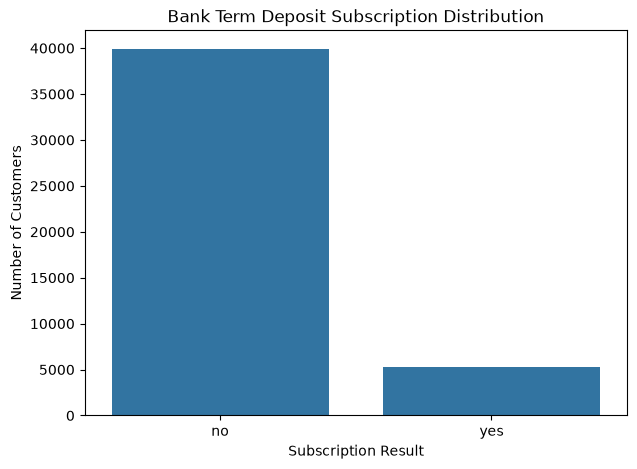

SUBSCRIPTION COUNTS:
y
no     39922
yes     5289
Name: count, dtype: int64

SUBSCRIPTION PERCENTAGES:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


In [10]:
# Target variable distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="y")

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscription Result")
plt.ylabel("Number of Customers")
plt.show()

print("SUBSCRIPTION COUNTS:")
print(df["y"].value_counts())

print("\nSUBSCRIPTION PERCENTAGES:")
print(df["y"].value_counts(normalize=True) * 100)


**Interpretation**

The chart shows that most customers did not subscribe to a bank term deposit. Out of 45,211 customers, 39,922 (88.30%) did not subscribe, while only 5,289 (11.70%) subscribed. This shows that the dataset is imbalanced because the number of customers who did not subscribe is much higher than the number who did. This is important to consider when training and evaluating the machine learning models because accuracy alone may not be enough to measure model performance.


## 4.2 Age Distribution of Bank Customers

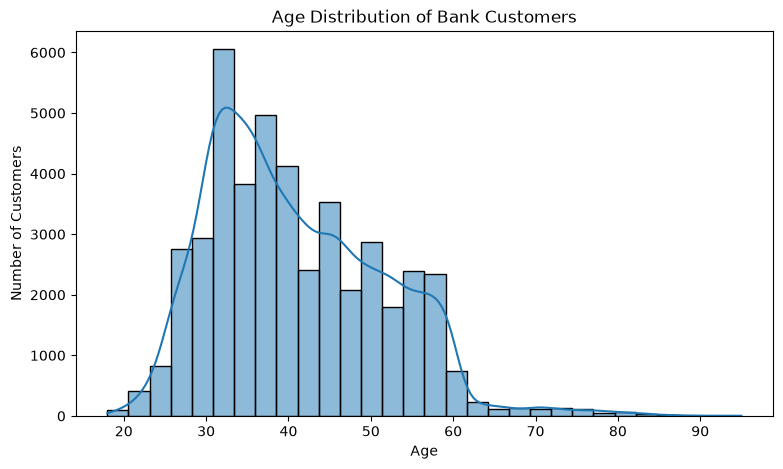

AGE SUMMARY:
count    45211.000000
mean        40.936210
std         10.618762
min         18.000000
25%         33.000000
50%         39.000000
75%         48.000000
max         95.000000
Name: age, dtype: float64


In [11]:
# Age distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="age", bins=30, kde=True)

plt.title("Age Distribution of Bank Customers")
plt.xlabel("Age")
plt.ylabel("Number of Customers")
plt.show()

print("AGE SUMMARY:")
print(df["age"].describe())


**Interpretation**

The histogram shows that most bank customers are between their late 20s and late 50s, with many customers around the early 30s. Based on the summary statistics, the average customer age is approximately 41 years, while the median age is 39 years. The youngest customer is 18 years old, and the oldest is 95 years old. This shows that the dataset includes customers from different age groups, but most of them are middle-aged adults.


## 4.3 Customer Distribution by Job

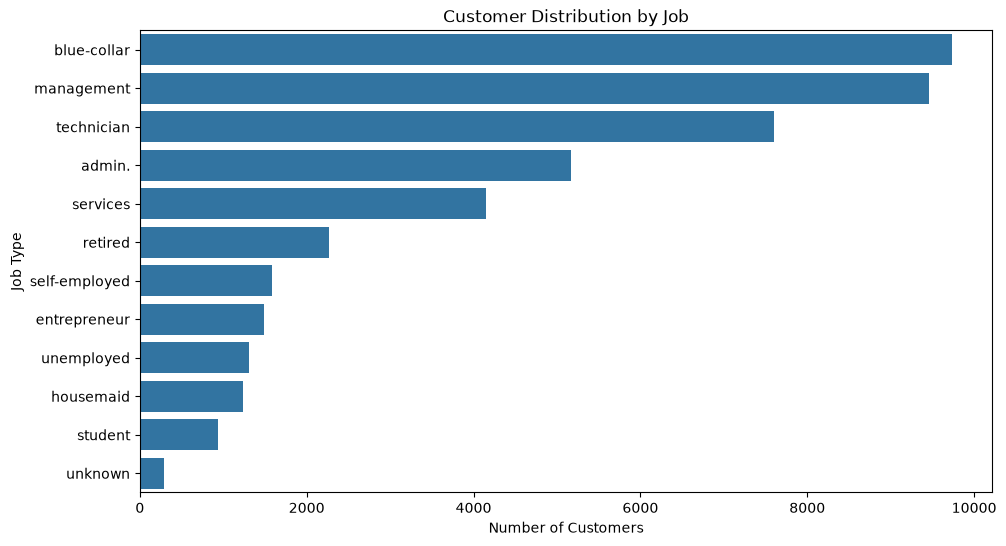

CUSTOMER COUNT BY JOB:
job
blue-collar      9732
management       9458
technician       7597
admin.           5171
services         4154
retired          2264
self-employed    1579
entrepreneur     1487
unemployed       1303
housemaid        1240
student           938
unknown           288
Name: count, dtype: int64


In [12]:
# Customer distribution by job
plt.figure(figsize=(11, 6))
sns.countplot(
    data=df,
    y="job",
    order=df["job"].value_counts().index
)

plt.title("Customer Distribution by Job")
plt.xlabel("Number of Customers")
plt.ylabel("Job Type")
plt.show()

print("CUSTOMER COUNT BY JOB:")
print(df["job"].value_counts())


**Interpretation**

The chart shows the distribution of customers according to their job types. Blue-collar workers have the highest number of customers with 9,732, followed closely by management employees with 9,458. Technicians are also well represented, with 7,597 customers. On the other hand, the unknown job category has the lowest count, with only 288 customers. This shows that blue-collar, management, and technician workers make up a large portion of the bank's customer records.


## 4.4 Term Deposit Subscription by Job Type

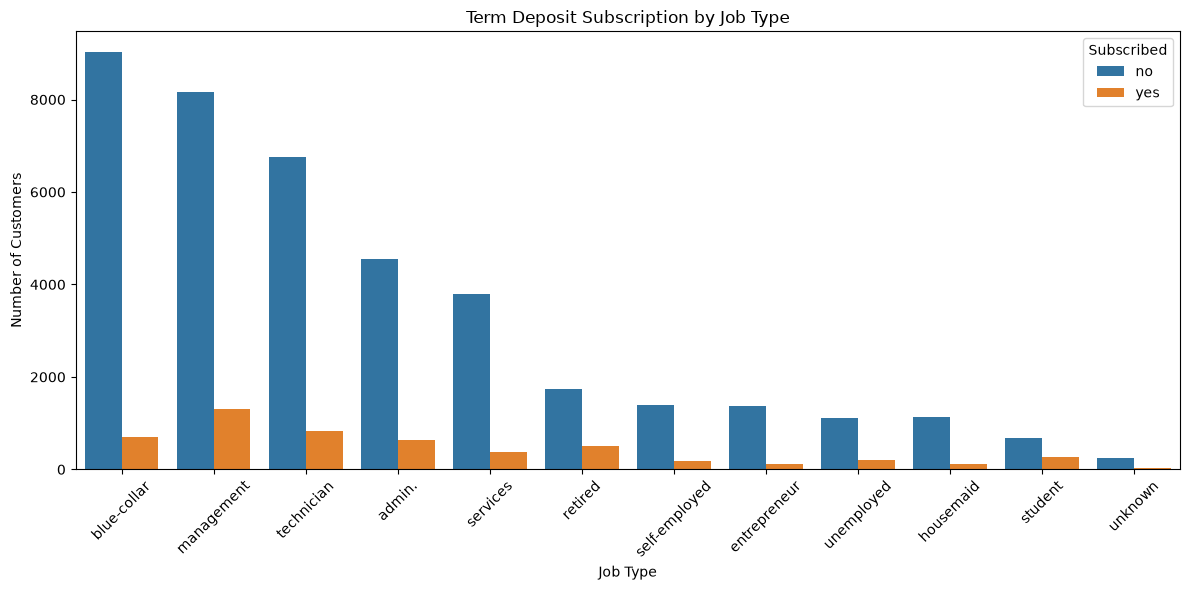

In [13]:
# Subscription results by job
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="job",
    hue="y",
    order=df["job"].value_counts().index
)

plt.title("Term Deposit Subscription by Job Type")
plt.xlabel("Job Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=45)
plt.legend(title="Subscribed")
plt.tight_layout()
plt.show()


**Interpretation**

The chart compares the number of customers who subscribed and did not subscribe to a term deposit across different job categories. Management employees have the highest number of subscribers, followed by technicians and blue-collar workers. However, blue-collar workers have the highest total number of customers, with most of them not subscribing. The chart also shows that non-subscribers outnumber subscribers in every job category. This chart compares counts, not subscription rates, so the differences may also reflect the number of customers in each job category.


## 4.5 Distribution of Customer Account Balances

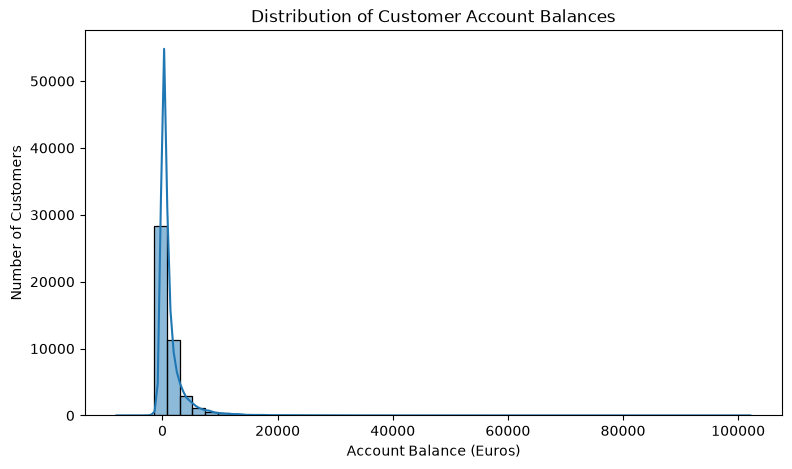

BALANCE SUMMARY:
count     45211.000000
mean       1362.272058
std        3044.765829
min       -8019.000000
25%          72.000000
50%         448.000000
75%        1428.000000
max      102127.000000
Name: balance, dtype: float64


In [14]:
# Account balance distribution
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="balance", bins=50, kde=True)

plt.title("Distribution of Customer Account Balances")
plt.xlabel("Account Balance (Euros)")
plt.ylabel("Number of Customers")
plt.show()

print("BALANCE SUMMARY:")
print(df["balance"].describe())


**Interpretation**

The histogram shows that most customers have account balances concentrated around the lower values, while only a small number have very high balances. The average balance is approximately €1,362.27, which is higher than the median of €448. This suggests that some customers with high balances increase the overall average. The dataset also contains negative balances, with the lowest being -€8,019, while the highest balance reaches €102,127. Overall, the distribution is highly right-skewed, meaning that most customers have lower balances and only a few have much higher balances.


## 4.6 Term Deposit Subscription Rate by Age Group

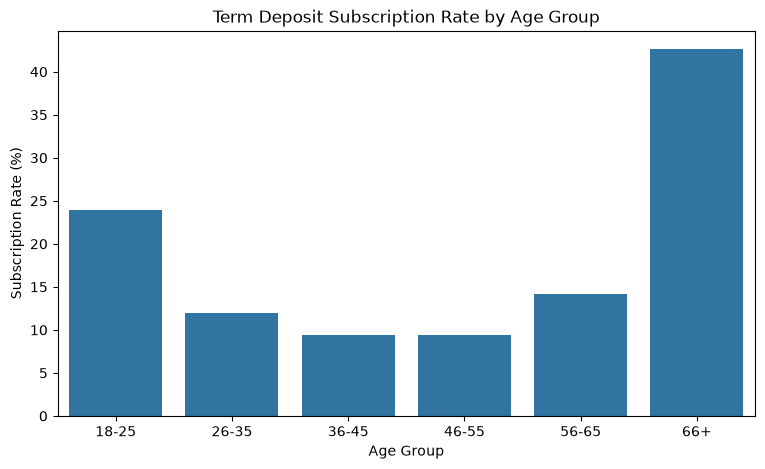

  Age Group  Subscription Rate
0     18-25          23.952096
1     26-35          12.003083
2     36-45           9.389434
3     46-55           9.352744
4     56-65          14.123885
5       66+          42.609854


In [15]:
# Create age groups and calculate subscription rates
df["age_group"] = pd.cut(
    df["age"],
    bins=[0, 25, 35, 45, 55, 65, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56-65", "66+"]
)

age_subscription = (
    df.groupby("age_group", observed=False)["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .reset_index()
)

age_subscription.columns = ["Age Group", "Subscription Rate"]

plt.figure(figsize=(9, 5))
sns.barplot(
    data=age_subscription,
    x="Age Group",
    y="Subscription Rate"
)

plt.title("Term Deposit Subscription Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Subscription Rate (%)")
plt.show()

print(age_subscription)


**Interpretation**

The chart shows the percentage of customers who subscribed to a term deposit across different age groups. Customers aged 66 and above have the highest subscription rate at approximately 42.61%, followed by those aged 18–25 at approximately 23.95%. Meanwhile, customers aged 36–45 and 46–55 have the lowest subscription rates, at approximately 9.39% and 9.35%. This shows that subscription rates vary across age groups in this dataset. These patterns show association and do not prove that age causes a customer to subscribe.


## 4.7 Correlation Heatmap of Numerical Variables

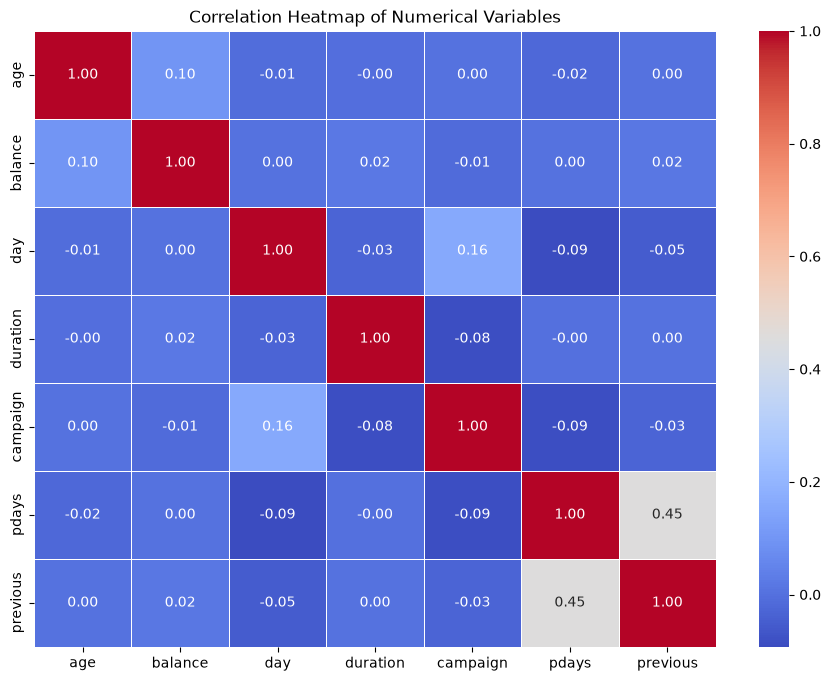

In [16]:
# Correlation heatmap
numerical_df = df.select_dtypes(include="number")
correlation_matrix = numerical_df.corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.show()


**Interpretation**

The correlation heatmap shows the relationships between the numerical variables in the dataset. Most variables have weak or very weak correlations with one another. The strongest positive relationship is between `pdays` and `previous`, with a correlation value of approximately 0.45. The relationship between `day` and `campaign` is also positive but weak, with a value of approximately 0.16. Overall, the heatmap shows that most numerical variables do not have strong linear relationships with each other. The heatmap only shows correlations among numerical variables and does not show their relationship with the target variable.


## 4.8 EDA Summary

The visualizations show the distribution of the target variable and several customer characteristics. The target variable is imbalanced, with substantially more customers who did not subscribe than customers who subscribed. Age-group subscription rates also vary, and the numerical correlation heatmap shows that most pairs of numerical variables have weak linear relationships.

These findings will be considered during feature engineering, model selection, and model evaluation.


# 5. Feature Engineering and Selection

This section prepares the dataset for machine learning by separating the input features from the target variable. Numerical and categorical features will be identified so that appropriate preprocessing methods can be applied.

## 5.1 Separating Features and Target Variable

The target variable is `y`, which indicates whether a customer subscribed to a term deposit. The remaining 15 input features listed in the approved project proposal will be used for prediction.

The `duration` column will be excluded because its value is only known after the call. Including it could cause data leakage and would not be suitable for the intended prediction before or during customer outreach.

In [17]:
# Separate input features and target variable
X = df.drop(columns=["y", "duration", "age_group"])
y = df["y"]

# Display dataset shapes
print("FEATURE DATASET SHAPE:", X.shape)
print("TARGET DATASET SHAPE:", y.shape)

# Display input features
print("\nINPUT FEATURES:")
print(X.columns.tolist())

# Display target values
print("\nTARGET VALUES:")
print(y.value_counts())

FEATURE DATASET SHAPE: (45211, 15)
TARGET DATASET SHAPE: (45211,)

INPUT FEATURES:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous', 'poutcome']

TARGET VALUES:
y
no     39922
yes     5289
Name: count, dtype: int64


In [18]:
# Identify numerical and categorical features
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str", "category"]).columns.tolist()

# Display numerical features
print("NUMERICAL FEATURES:")
print(numeric_features)
print("Total numerical features:", len(numeric_features))

# Display categorical features
print("\nCATEGORICAL FEATURES:")
print(categorical_features)
print("Total categorical features:", len(categorical_features))

NUMERICAL FEATURES:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']
Total numerical features: 6

CATEGORICAL FEATURES:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Total categorical features: 9


In [19]:
# Create a new feature based on previous campaign contact
X["was_previously_contacted"] = (X["pdays"] != -1).astype(int)

# Display the new feature's values
print("PREVIOUSLY CONTACTED FEATURE:")
print(X["was_previously_contacted"].value_counts())

# Display the updated feature dataset shape
print("\nUPDATED FEATURE DATASET SHAPE:", X.shape)

PREVIOUSLY CONTACTED FEATURE:
was_previously_contacted
0    36954
1     8257
Name: count, dtype: int64

UPDATED FEATURE DATASET SHAPE: (45211, 16)


In [20]:
# Update numerical and categorical feature lists
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "str", "category"]).columns.tolist()

print("UPDATED NUMERICAL FEATURES:")
print(numeric_features)
print("Total numerical features:", len(numeric_features))

print("\nUPDATED CATEGORICAL FEATURES:")
print(categorical_features)
print("Total categorical features:", len(categorical_features))

print("\nTOTAL INPUT FEATURES:", len(numeric_features) + len(categorical_features))

UPDATED NUMERICAL FEATURES:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous', 'was_previously_contacted']
Total numerical features: 7

UPDATED CATEGORICAL FEATURES:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']
Total categorical features: 9

TOTAL INPUT FEATURES: 16


## 5.2 Feature Preprocessing

Numerical and categorical features require different preprocessing methods. StandardScaler will be used to scale numerical features, while One-Hot Encoding will convert categorical features into numerical representations.

A ColumnTransformer will combine these preprocessing steps. The transformations will be fitted using only the training data to prevent data leakage.

### Importing and Preparing Preprocessing Tools

In [21]:
# Import preprocessing tools from Scikit-learn
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [22]:
# Create preprocessing transformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


### 5.3 Feature Engineering Summary

The dataset was prepared by separating the target variable from the input features. The 15 input features listed in the approved proposal were retained, excluding the `duration` column to prevent data leakage.

One additional feature, `was_previously_contacted`, was created using the `pdays` column. This indicates whether a customer had been contacted during a previous campaign.

The final input dataset contains 16 features, consisting of 7 numerical features and 9 categorical features. StandardScaler will be used for numerical features, while One-Hot Encoding will be applied to categorical features.

The preprocessing transformer will be fitted using only the training data to prevent data leakage.

# 6. Model Selection

This project will use two classification algorithms: Logistic Regression and Random Forest. These models will be trained and compared to determine which one performs better in predicting whether a customer will subscribe to a term deposit.

## 6.1 Selected Machine Learning Algorithms

### Logistic Regression

Logistic Regression is a classification algorithm that predicts the probability of an outcome. In this project, it will be applied to estimate whether a customer is likely to subscribe to a term deposit based on the available customer and campaign information. It will serve as our first model for comparison.

### Random Forest

Random Forest is a classification algorithm that combines multiple decision trees to produce a prediction. Each tree will make its own prediction, and the final result will be based on the combined votes of the trees. It will serve as our second model for comparison with Logistic Regression.

# 7. Model Training

This section prepares the dataset for training and evaluating the selected machine learning models. The data will be divided into training and testing sets using an 80/20 split. Stratified sampling will be applied to maintain the same target class distribution in both sets.

## 7.1 Splitting the Dataset

In [23]:
# Import train_test_split
from sklearn.model_selection import train_test_split

print("Train-test split function imported successfully!")

Train-test split function imported successfully!


In [24]:
# Split the dataset into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the dataset sizes
print("TRAINING SET:")
print("Features:", X_train.shape)
print("Target:", y_train.shape)

print("\nTESTING SET:")
print("Features:", X_test.shape)
print("Target:", y_test.shape)

TRAINING SET:
Features: (36168, 16)
Target: (36168,)

TESTING SET:
Features: (9043, 16)
Target: (9043,)


## 7.2 Creating Machine Learning Pipelines

Pipelines will combine the preprocessing steps and classification algorithms. This allows the numerical features to be scaled and the categorical features to be encoded before model training.

The preprocessing steps will be fitted using the training data only to prevent data leakage.

In [25]:
# Import required machine learning tools
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

print("Machine learning tools imported successfully!")

Machine learning tools imported successfully!


In [26]:
# Create Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Create Random Forest pipeline
random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(random_state=42))
])

print("Logistic Regression pipeline created successfully!")
print("Random Forest pipeline created successfully!")

Logistic Regression pipeline created successfully!
Random Forest pipeline created successfully!


## 7.3 Training the Machine Learning Models

The Logistic Regression and Random Forest models will now be trained using the training dataset. During this process, the preprocessing steps will also be fitted to the training data before the models learn the patterns.

In [27]:
# Train the Logistic Regression model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

# Train the Random Forest model
random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Logistic Regression model trained successfully!
Random Forest model trained successfully!


## 7.4 Making Predictions

After training the models, the testing dataset will be used to generate predictions. These predictions will later be compared with the actual target values to evaluate how well each model performs on unseen data.

In [28]:
# Generate predictions using Logistic Regression
logistic_predictions = logistic_model.predict(X_test)

# Generate predictions using Random Forest
random_forest_predictions = random_forest_model.predict(X_test)

print("Predictions generated successfully!")

print("\nLOGISTIC REGRESSION PREDICTIONS:")
print(logistic_predictions[:10])

print("\nRANDOM FOREST PREDICTIONS:")
print(random_forest_predictions[:10])

Predictions generated successfully!

LOGISTIC REGRESSION PREDICTIONS:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']

RANDOM FOREST PREDICTIONS:
['no' 'no' 'no' 'no' 'no' 'no' 'no' 'yes' 'no' 'no']


### 7.5 Model Training Summary

The dataset was divided into training and testing sets using an 80/20 split with stratified sampling. Two machine learning models, Logistic Regression and Random Forest, were prepared using preprocessing pipelines.

The pipelines applied StandardScaler to numerical features and One-Hot Encoding to categorical features. The preprocessing steps were fitted using only the training data to prevent data leakage.

Both models were successfully trained using the training dataset and generated predictions using the testing dataset. Their performance will be evaluated and compared in the next section.

# 8. Model Evaluation and Tuning

## 8.1 Importing Evaluation Metrics

In [29]:
# Import evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


## 8.2 Evaluating Models on Training Data

The models will first be evaluated using the training dataset. These results will help us check how well each model learned from the data and identify possible signs of overfitting. Training performance will be compared with testing performance later.

In [30]:
# Generate predictions using the training dataset
logistic_train_predictions = logistic_model.predict(X_train)
random_forest_train_predictions = random_forest_model.predict(X_train)

# Calculate training performance metrics
logistic_train_accuracy = accuracy_score(y_train, logistic_train_predictions)
logistic_train_precision = precision_score(y_train, logistic_train_predictions, pos_label="yes", zero_division=0)
logistic_train_recall = recall_score(y_train, logistic_train_predictions, pos_label="yes", zero_division=0)
logistic_train_f1 = f1_score(y_train, logistic_train_predictions, pos_label="yes", zero_division=0)

random_forest_train_accuracy = accuracy_score(y_train, random_forest_train_predictions)
random_forest_train_precision = precision_score(y_train, random_forest_train_predictions, pos_label="yes", zero_division=0)
random_forest_train_recall = recall_score(y_train, random_forest_train_predictions, pos_label="yes", zero_division=0)
random_forest_train_f1 = f1_score(y_train, random_forest_train_predictions, pos_label="yes", zero_division=0)

# Display the results
print("LOGISTIC REGRESSION - TRAINING PERFORMANCE")
print(f"Accuracy:  {logistic_train_accuracy:.4f}")
print(f"Precision: {logistic_train_precision:.4f}")
print(f"Recall:    {logistic_train_recall:.4f}")
print(f"F1-Score:  {logistic_train_f1:.4f}")

print("\nRANDOM FOREST - TRAINING PERFORMANCE")
print(f"Accuracy:  {random_forest_train_accuracy:.4f}")
print(f"Precision: {random_forest_train_precision:.4f}")
print(f"Recall:    {random_forest_train_recall:.4f}")
print(f"F1-Score:  {random_forest_train_f1:.4f}")

LOGISTIC REGRESSION - TRAINING PERFORMANCE
Accuracy:  0.8924
Precision: 0.6468
Recall:    0.1766
F1-Score:  0.2774

RANDOM FOREST - TRAINING PERFORMANCE
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-Score:  1.0000


## 8.3 Evaluating Testing Performance

The trained models will be evaluated using the testing dataset to measure how well they perform on unseen data. Accuracy, precision, recall, and F1-score will be calculated for both models.

These results will help determine whether the models can generalize to new customer records.

In [32]:
# Generate predictions using the testing dataset
logistic_test_predictions = logistic_model.predict(X_test)
random_forest_test_predictions = random_forest_model.predict(X_test)

# Calculate Logistic Regression testing metrics
logistic_test_accuracy = accuracy_score(y_test, logistic_test_predictions)
logistic_test_precision = precision_score(
    y_test, logistic_test_predictions, pos_label="yes", zero_division=0
)
logistic_test_recall = recall_score(
    y_test, logistic_test_predictions, pos_label="yes", zero_division=0
)
logistic_test_f1 = f1_score(
    y_test, logistic_test_predictions, pos_label="yes", zero_division=0
)

# Calculate Random Forest testing metrics
random_forest_test_accuracy = accuracy_score(y_test, random_forest_test_predictions)
random_forest_test_precision = precision_score(
    y_test, random_forest_test_predictions, pos_label="yes", zero_division=0
)
random_forest_test_recall = recall_score(
    y_test, random_forest_test_predictions, pos_label="yes", zero_division=0
)
random_forest_test_f1 = f1_score(
    y_test, random_forest_test_predictions, pos_label="yes", zero_division=0
)

# Display Logistic Regression results
print("LOGISTIC REGRESSION - TESTING PERFORMANCE")
print(f"Accuracy:  {logistic_test_accuracy:.4f}")
print(f"Precision: {logistic_test_precision:.4f}")
print(f"Recall:    {logistic_test_recall:.4f}")
print(f"F1-Score:  {logistic_test_f1:.4f}")

# Display Random Forest results
print("\nRANDOM FOREST - TESTING PERFORMANCE")
print(f"Accuracy:  {random_forest_test_accuracy:.4f}")
print(f"Precision: {random_forest_test_precision:.4f}")
print(f"Recall:    {random_forest_test_recall:.4f}")
print(f"F1-Score:  {random_forest_test_f1:.4f}")

LOGISTIC REGRESSION - TESTING PERFORMANCE
Accuracy:  0.8934
Precision: 0.6643
Recall:    0.1796
F1-Score:  0.2827

RANDOM FOREST - TESTING PERFORMANCE
Accuracy:  0.8925
Precision: 0.6103
Recall:    0.2250
F1-Score:  0.3287


## 8.4 Confusion Matrix

A confusion matrix is used to examine the predictions made by each model. It shows the number of correct and incorrect predictions for both classes: customers who subscribed and customers who did not subscribe.

This helps identify false positives and false negatives and provides a clearer understanding of model performance.

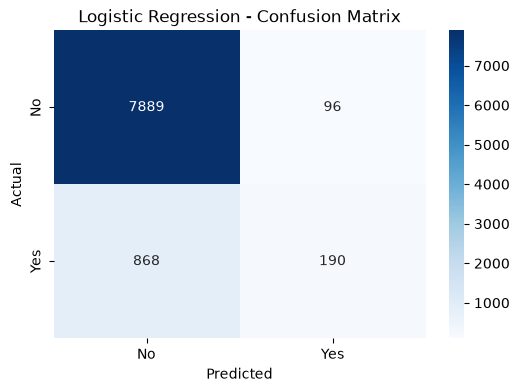

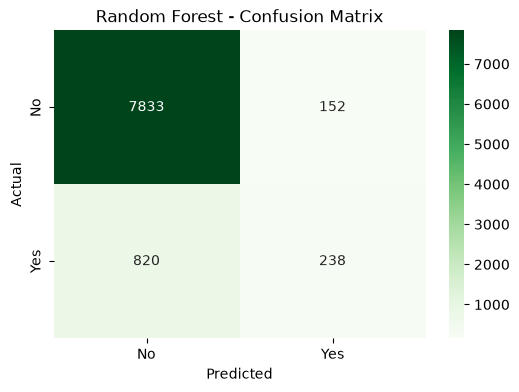

In [38]:
# Generate confusion matrices
logistic_cm = confusion_matrix(
    y_test, logistic_test_predictions, labels=["no", "yes"]
)

random_forest_cm = confusion_matrix(
    y_test, random_forest_test_predictions, labels=["no", "yes"]
)

# Display Logistic Regression confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    logistic_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)
plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Display Random Forest confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    random_forest_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)
plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

### Confusion Matrix Interpretation

The confusion matrices show how well each model classified customers who subscribed and those who did not subscribe.

Logistic Regression correctly identified 190 customers who subscribed and 7,889 customers who did not subscribe. However, it failed to identify 868 actual subscribers.

Random Forest correctly identified 238 customers who subscribed and 7,833 customers who did not subscribe. It also had 820 false negatives.

Compared with Logistic Regression, Random Forest identified more actual subscribers but also produced more false positives. This resulted in higher recall and F1-score, while Logistic Regression achieved higher precision.

These results show that both models have difficulty identifying customers who subscribed, which may be partly related to the imbalance in the target variable.

## 8.5 Cross-Validation and Hyperparameter Tuning

Hyperparameter tuning will be performed on the Random Forest model using RandomizedSearchCV. This method tests different combinations of model settings to find a combination that produces better results.

Three-fold cross-validation will be used to evaluate the different combinations. The F1-score will serve as the scoring metric because the dataset has an imbalanced target variable.

The search will use only the training dataset to prevent data leakage. The testing dataset will remain untouched until the final evaluation.

In [39]:
# Import tools for cross-validation and hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer

print("Hyperparameter tuning tools imported successfully!")

Hyperparameter tuning tools imported successfully!


In [40]:
# Define the hyperparameter combinations for Random Forest
param_distributions = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, 20, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__class_weight": [None, "balanced", "balanced_subsample"]
}

print("Hyperparameter combinations defined successfully!")

Hyperparameter combinations defined successfully!


In [41]:
# Configure 3-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Use F1-score with "yes" as the positive class
f1_scorer = make_scorer(f1_score, pos_label="yes")

# Configure RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=random_forest_model,
    param_distributions=param_distributions,
    n_iter=10,
    scoring=f1_scorer,
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("RandomizedSearchCV configured successfully!")

RandomizedSearchCV configured successfully!


In [42]:
# Perform hyperparameter tuning using training data only
random_search.fit(X_train, y_train)

print("Hyperparameter tuning completed successfully!")

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Hyperparameter tuning completed successfully!


### 8.5.1 Best Hyperparameters and Cross-Validation Results

After completing the hyperparameter search, the best combination of hyperparameters and its corresponding cross-validation F1-score will be displayed. These results will help identify the Random Forest configuration that performed best during cross-validation.

In [43]:
# Display the best hyperparameters
print("BEST HYPERPARAMETERS:")
print(random_search.best_params_)

# Display the best cross-validation F1-score
print("\nBEST CROSS-VALIDATION F1-SCORE:")
print(f"{random_search.best_score_:.4f}")

BEST HYPERPARAMETERS:
{'classifier__n_estimators': 100, 'classifier__min_samples_split': 5, 'classifier__min_samples_leaf': 4, 'classifier__max_depth': None, 'classifier__class_weight': 'balanced_subsample'}

BEST CROSS-VALIDATION F1-SCORE:
0.4694


## 8.6 Evaluating the Tuned Random Forest Model

The best Random Forest configuration obtained from RandomizedSearchCV will be evaluated using the testing dataset. The same evaluation metrics used for the baseline models will be applied to determine whether hyperparameter tuning improved the model's performance on unseen data.

In [44]:
# Retrieve the best Random Forest model
tuned_random_forest = random_search.best_estimator_

print("Tuned Random Forest model retrieved successfully!")

Tuned Random Forest model retrieved successfully!


In [45]:
# Generate predictions using the tuned model
tuned_rf_predictions = tuned_random_forest.predict(X_test)

print("Tuned Random Forest predictions generated successfully!")

Tuned Random Forest predictions generated successfully!


In [46]:
# Calculate testing performance metrics
tuned_rf_accuracy = accuracy_score(y_test, tuned_rf_predictions)

tuned_rf_precision = precision_score(
    y_test, tuned_rf_predictions, pos_label="yes", zero_division=0
)

tuned_rf_recall = recall_score(
    y_test, tuned_rf_predictions, pos_label="yes", zero_division=0
)

tuned_rf_f1 = f1_score(
    y_test, tuned_rf_predictions, pos_label="yes", zero_division=0
)

# Display results
print("TUNED RANDOM FOREST - TESTING PERFORMANCE")
print(f"Accuracy:  {tuned_rf_accuracy:.4f}")
print(f"Precision: {tuned_rf_precision:.4f}")
print(f"Recall:    {tuned_rf_recall:.4f}")
print(f"F1-Score:  {tuned_rf_f1:.4f}")

TUNED RANDOM FOREST - TESTING PERFORMANCE
Accuracy:  0.8691
Precision: 0.4476
Recall:    0.5085
F1-Score:  0.4761


### 8.6.1 Tuned Random Forest Performance Interpretation

The tuned Random Forest model achieved an accuracy of 86.91%, precision of 44.76%, recall of 50.85%, and F1-score of 47.61% on the testing dataset.

Compared with the original Random Forest model, the tuned model achieved higher recall and F1-score but lower accuracy and precision.

The improvement in recall indicates that the tuned model was able to identify more customers who actually subscribed to a term deposit. However, the lower precision means that it also produced more false positive predictions.

Overall, hyperparameter tuning improved the model's ability to identify actual subscribers and provided a better balance between precision and recall.

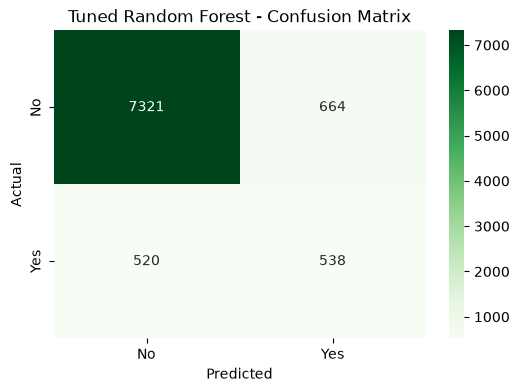

In [48]:
# Generate confusion matrix for the tuned Random Forest
tuned_rf_cm = confusion_matrix(
    y_test,
    tuned_rf_predictions,
    labels=["no", "yes"]
)

# Display confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    tuned_rf_cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Tuned Random Forest - Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 8.7 Overall Model Comparison

The three model configurations will be compared using their testing performance: Logistic Regression, the original Random Forest, and the tuned Random Forest.

Accuracy, precision, recall, and F1-score will be used to determine which model provides the best performance for predicting term deposit subscriptions.

In [49]:
# Create a comparison table for all three models
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "Accuracy": [
        logistic_test_accuracy,
        random_forest_test_accuracy,
        tuned_rf_accuracy
    ],
    "Precision": [
        logistic_test_precision,
        random_forest_test_precision,
        tuned_rf_precision
    ],
    "Recall": [
        logistic_test_recall,
        random_forest_test_recall,
        tuned_rf_recall
    ],
    "F1-Score": [
        logistic_test_f1,
        random_forest_test_f1,
        tuned_rf_f1
    ]
})

# Display comparison table
model_comparison.set_index("Model").round(4)

,Accuracy,Precision,Recall,F1-Score
Model,,,,
Logistic Regression,0.8934,0.6643,0.1796,0.2827
Original Random Forest,0.8925,0.6103,0.2250,0.3287
Tuned Random Forest,0.8691,0.4476,0.5085,0.4761


### 8.7.1 Overall Model Comparison Interpretation

Based on the testing results, Logistic Regression achieved the highest accuracy of 89.34% and precision of 66.43%. However, it had the lowest recall of 17.96% and F1-score of 28.27%.

The original Random Forest achieved an accuracy of 89.25%, precision of 61.03%, recall of 22.50%, and F1-score of 32.87%.

After hyperparameter tuning, Random Forest achieved an accuracy of 86.91%, precision of 44.76%, recall of 50.85%, and F1-score of 47.61%.

The tuned Random Forest achieved the highest recall and F1-score among the three models. Although its accuracy and precision decreased, it was able to identify more customers who actually subscribed to a term deposit.

Based on the F1-score, the tuned Random Forest is selected as the best-performing model for this project. However, its lower precision should also be considered when interpreting its predictions.

## 8.8 Error Analysis

The tuned Random Forest model achieved the highest F1-score among the three models. However, it still made incorrect predictions.

Based on its confusion matrix, the model produced 664 false positives and 520 false negatives.

False positives are customers predicted to subscribe who actually did not subscribe. False negatives are customers who actually subscribed but were predicted not to subscribe.

These errors show that the model is not always accurate. False positives may lead to unnecessary marketing efforts, while false negatives may cause the bank to miss potential subscribers.

Although the tuned Random Forest performed better in identifying subscribers, its predictions should still be reviewed carefully.

## 8.9 Model Limitations

Despite the results, the BankReach models have several limitations:

1. Class Imbalance: The dataset contains significantly more customers who did not subscribe than those who subscribed. This makes it harder for the models to identify potential subscribers.

2. Dataset Limitations: The dataset contains historical bank marketing data from Portugal. The results may not represent current banking customers or customers in other countries.

3. Limited Features: The models only use the available dataset features. Other factors that may influence a customer's decision, such as personal preferences and financial circumstances, are not fully represented.

4. Prediction Errors: Even the best-performing model still produces false positives and false negatives. Its predictions are not always correct.

5. Overfitting: The original Random Forest achieved perfect scores on the training data but performed much worse on the test data, indicating overfitting.

6. Academic Use: This project is intended for educational purposes and campaign-planning support. It should not be used as the sole basis for real banking decisions.